In [1]:
#  Explore life expectancy
# Reads: ../data/life-expectancy.csv | Saves: nothing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
# load
life = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\life-expectancy.csv")
life = life.rename(columns={"Life expectancy": "life_exp"})


print("FIRST ROWS")
print(life.head())

FIRST ROWS
        Entity Code  Year  life_exp
0  Afghanistan  AFG  1950   28.1563
1  Afghanistan  AFG  1951   28.5836
2  Afghanistan  AFG  1952   29.0138
3  Afghanistan  AFG  1953   29.4521
4  Afghanistan  AFG  1954   29.6975


In [3]:
# 2. Shape, dtypes, missing values
print("\n SHAPE")
print(life.shape)

print("\n INFO ")
life.info()

print("\n MISSING VALUES ")
print(life.isna().sum())

# coverage
print("\n COVERAGE ")
print("Entities:", life["Entity"].nunique())
print("Years:", life["Year"].min(), "to", life["Year"].max())



 SHAPE
(21565, 4)

 INFO 
<class 'pandas.DataFrame'>
RangeIndex: 21565 entries, 0 to 21564
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Entity    21565 non-null  str    
 1   Code      20217 non-null  str    
 2   Year      21565 non-null  int64  
 3   life_exp  21565 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 958.7 KB

 MISSING VALUES 
Entity         0
Code        1348
Year           0
life_exp       0
dtype: int64

 COVERAGE 
Entities: 265
Years: 1543 to 2023


In [4]:
# Aggregates (World, regions) have no country code or an OWID_ code
is_aggregate = life["Code"].isna() | life["Code"].astype(str).str.startswith("OWID")
print("Aggregate rows (not countries):", is_aggregate.sum())
print("Country rows:", (~is_aggregate).sum())
print("Aggregate names:", sorted(life.loc[is_aggregate, "Entity"].unique())[:15])

Aggregate rows (not countries): 2113
Country rows: 19452
Aggregate names: ['Africa', 'Americas', 'Asia', 'England and Wales', 'Europe', 'High-and-upper-middle-income countries', 'High-income countries', 'Kosovo', 'Land-locked Developing Countries (LLDC)', 'Latin America and the Caribbean', 'Least developed countries', 'Less developed regions', 'Less developed regions, excluding China', 'Less developed regions, excluding least developed countries', 'Low-and-Lower-middle-income countries']


In [5]:
# Work with countries only for the rest of this notebook
countries = life[~is_aggregate].copy()

In [6]:
# . Central tendency and spread 
print("\n DESCRIBE (countries only) ")
print(countries["life_exp"].describe().round(2))

mean_ = countries["life_exp"].mean()
median_ = countries["life_exp"].median()
std_ = countries["life_exp"].std()
skew_ = countries["life_exp"].skew()
print(f"\nMean:   {mean_:.2f}")
print(f"Median: {median_:.2f}")
print(f"Std:    {std_:.2f}")
print(f"Skew:   {skew_:.2f}  (negative = long tail to the left, positive = long tail to the right)")


 DESCRIBE (countries only) 
count    19452.00
mean        62.10
std         13.06
min         10.99
25%         52.95
50%         64.83
75%         72.18
max         86.37
Name: life_exp, dtype: float64

Mean:   62.10
Median: 64.83
Std:    13.06
Skew:   -0.61  (negative = long tail to the left, positive = long tail to the right)


In [7]:
#  Column names and types
print(" COLUMNS ")
print(life.dtypes)

 COLUMNS 
Entity          str
Code            str
Year          int64
life_exp    float64
dtype: object


In [8]:
life.head()

,Entity,Code,Year,life_exp
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975


In [9]:
#(rows, columns)
life.shape

(21565, 4)

In [10]:
life.info()

<class 'pandas.DataFrame'>
RangeIndex: 21565 entries, 0 to 21564
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Entity    21565 non-null  str    
 1   Code      20217 non-null  str    
 2   Year      21565 non-null  int64  
 3   life_exp  21565 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 958.7 KB


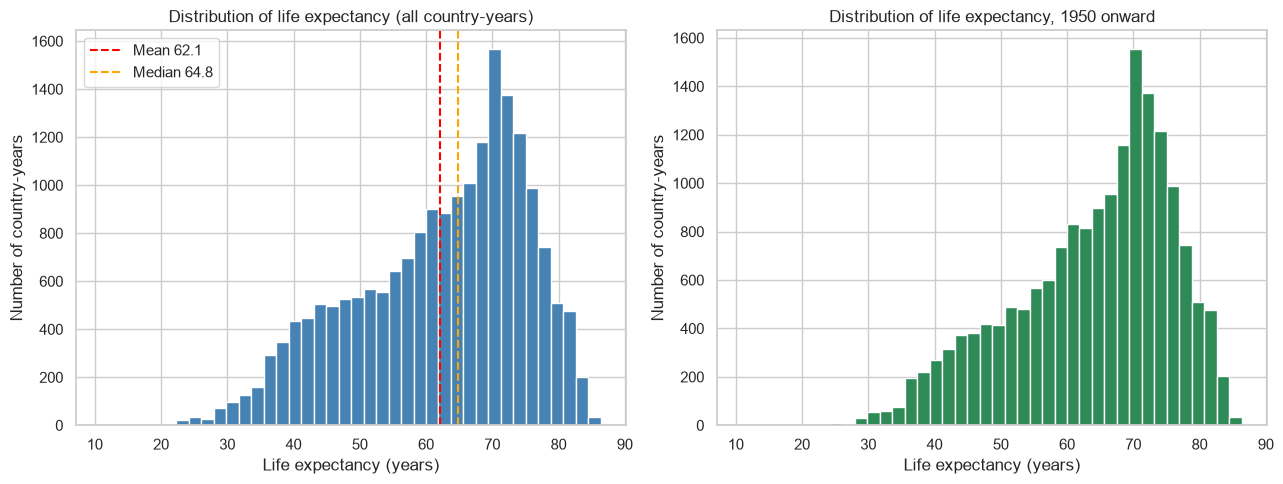

In [11]:

# Distribution plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: all country-years
# Each bar counts how many country-years fall in that range of life expectancy. The shape is skewed to the left: most country-years sit between about 65 and 80 years, with a long tail of low values down into the 20s and 30s. The mean (62.1) is below the median (64.8) because that low tail pulls the average down.

axes[0].hist(countries["life_exp"], bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(mean_, color="red", linestyle="--", label=f"Mean {mean_:.1f}")
axes[0].axvline(median_, color="orange", linestyle="--", label=f"Median {median_:.1f}")
axes[0].set_title("Distribution of life expectancy (all country-years)")
axes[0].set_xlabel("Life expectancy (years)")
axes[0].set_ylabel("Number of country-years")
axes[0].legend()

# Right: 1950 onward only (the period you will analyse)
# This is the period I will analyse. It looks very similar because about 90% of 
# the rows are already from 1950 or later. The very low values from earlier centuries are mostly gone, 
# but the shape is still left-skewed, 
# so life expectancy is not evenly spread: some country-years are far below the typical value.
since_1950 = countries[countries["Year"] >= 1950]
axes[1].hist(since_1950["life_exp"], bins=40, color="seagreen", edgecolor="white")
axes[1].set_title("Distribution of life expectancy, 1950 onward")
axes[1].set_xlabel("Life expectancy (years)")
axes[1].set_ylabel("Number of country-years")

plt.tight_layout()
plt.show()

### Chart 1: Distribution of life expectancy, all country-years

Left-skewed, continuous, approximately Normal (skew -0.61)

**What it shows:** each bar counts how many country-years (one country in one year) have a life expectancy in that range. The red dashed line is the mean (62.1 years) and the orange dashed line is the median (64.8 years).

**Shape:** skewed to the left. Most country-years sit between about 65 and 80 years, and a long tail of low values stretches down into the 20s and 30s.

**Why the mean is below the median:** the low tail pulls the average down, while the median stays near the middle of the data. This gap is a sign of left skew.

**What it tells me:** life expectancy is not evenly spread. A typical country-year is fairly high, but some are far lower.

### Chart 2: Distribution of life expectancy, 1950 onward
Left-skewed, approximately Normal

**What it shows:** the same histogram, using only the period I plan to analyse.

**Why it looks so similar to chart 1:** about 90% of the rows are already from 1950 or later. Only around 10% are older, so removing them changes the picture only slightly. The mean moves up a little (to about 63.9) and the median to about 66.5, because the oldest, lowest values are gone.

**Shape:** still skewed to the left, with most values between 65 and 80 years and a tail of low values.

**Why I use 1950 onward:** from 1950, nearly every country has data for every year. Before 1950, only a limited set of countries is covered, which would bias the results. This choice matters even more after I join this file with the other two.

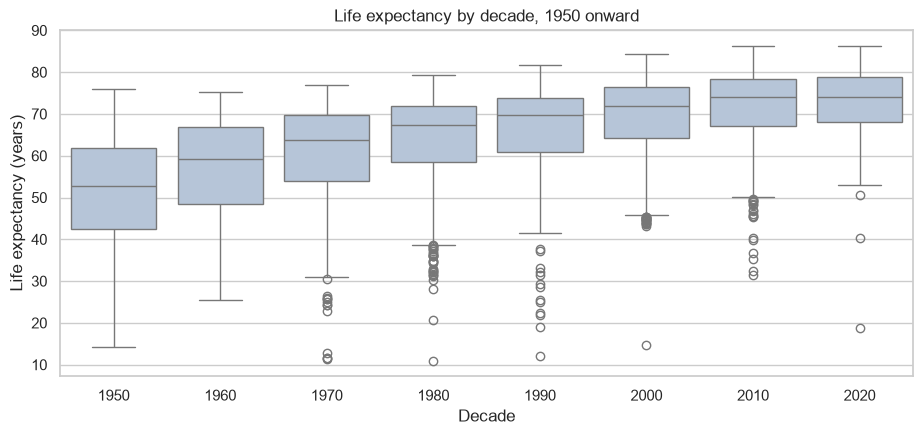

In [12]:
#  Spread over time 
countries["decade"] = (countries["Year"] // 10) * 10
recent = countries[countries["Year"] >= 1950]

plt.figure(figsize=(11, 4.5))
sns.boxplot(data=recent, x="decade", y="life_exp", color="lightsteelblue")
plt.title("Life expectancy by decade, 1950 onward")
plt.xlabel("Decade")
plt.ylabel("Life expectancy (years)")
plt.show()


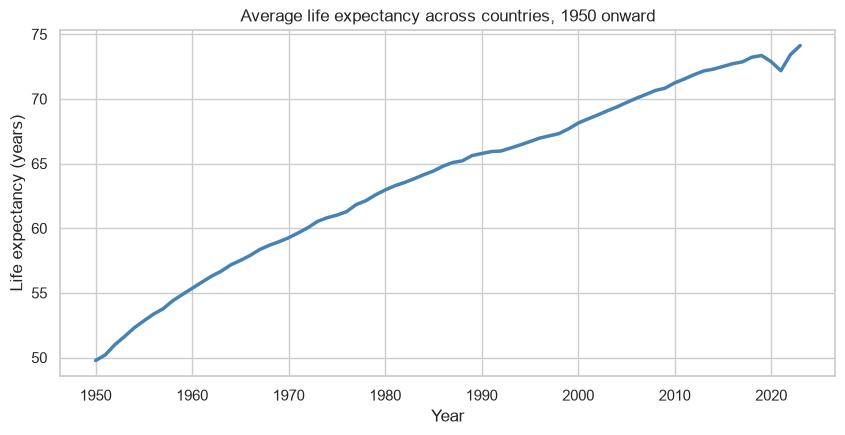

In [13]:
#  average life expectancy by year
avg_by_year = countries[countries["Year"] >= 1950].groupby("Year")["life_exp"].mean()

plt.figure(figsize=(10, 4.5))
plt.plot(avg_by_year.index, avg_by_year.values, color="steelblue", linewidth=2.5)
plt.title("Average life expectancy across countries, 1950 onward")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.show()

### Average life expectancy across countries, 1950 onward

**What it shows:** each point is the simple average life expectancy across all countries in that year.

**Trend:** the line rises almost without a break, from about 50 years in 1950 to about 74 years in the most recent year. Life expectancy has improved by roughly 24 years in under three-quarters of a century.

**The dip near the end:** the line dips slightly around 2020 to 2021, then recovers. This coincides with the COVID-19 period, but this chart alone cannot show the cause.

**Why it matters for my question:** the whole world got healthier over time, so when I compare countries I need to be careful. Part of the link between wealth and health could just be both rising with time.

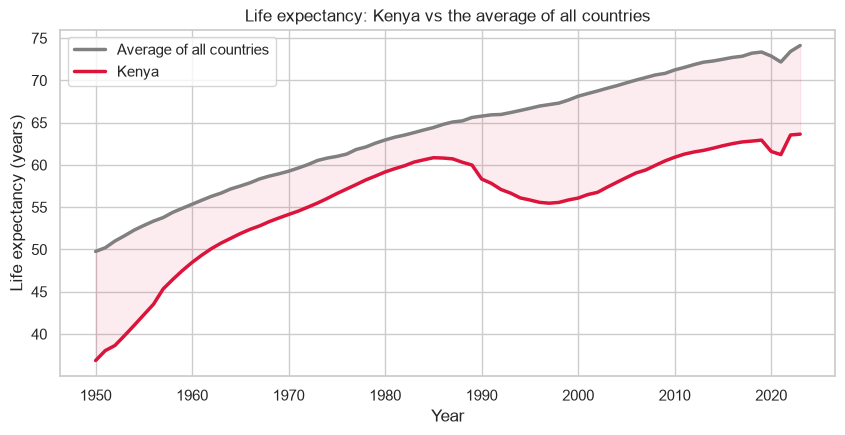

In [14]:
# Kenya vs the global average
kenya = countries[(countries["Entity"] == "Kenya") & (countries["Year"] >= 1950)].set_index("Year")["life_exp"]
compare = pd.DataFrame({"Kenya": kenya, "Average of all countries": avg_by_year}).dropna()

plt.figure(figsize=(10, 4.5))
plt.plot(compare.index, compare["Average of all countries"], color="gray", linewidth=2.5, label="Average of all countries")
plt.plot(compare.index, compare["Kenya"], color="crimson", linewidth=2.5, label="Kenya")
plt.fill_between(compare.index, compare["Kenya"], compare["Average of all countries"],
                 color="crimson", alpha=0.08)
plt.title("Life expectancy: Kenya vs the average of all countries")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.legend()
plt.show()


### Life expectancy, Kenya vs the average of all countries

**What it shows:** the grey line is the average of all countries, and the red line is Kenya. The pink band between them is the gap.

**Kenya is below the average in every year shown.** It starts about 13 years below in 1950 (roughly 37 vs 50 years).

**Catching up, then falling back:** Kenya's line climbs faster than the average until the mid-1980s, narrowing the gap to roughly 3 to 4 years. After that it falls, bottoming out at about 55 to 56 years in the late 1990s, while the average kept rising. The gap widens to roughly 11 years.

**Recovery:** Kenya then recovers steadily and ends at about 64 years, though it is still about 10 years below the average.

**What I cannot say from this chart:** I can see that Kenya's life expectancy fell in the late 1980s and 1990s, but the data does not tell me why. I should not state a cause in my write-up unless I find a source for it.

**Note:** the grey line gives every country equal weight, so it is not the same as the world average per person.

In [15]:
# Numbers to quote in the explanation
# Subtracts the average from Kenya for each year. 
# A negative number means Kenya is below the average, and a positive number means it is above.
gap = compare["Kenya"] - compare["Average of all countries"]

# These four lines print the start and end values. 
# compare.index[0] is the first year, 
# compare.index[-1] is the last, 
#  .iloc[0] and .iloc[-1] pick the first and last values.
#  round(..., 1) keeps one decimal plac
print("Average, first year:", compare.index[0], round(compare["Average of all countries"].iloc[0], 1))
print("Average, last year: ", compare.index[-1], round(compare["Average of all countries"].iloc[-1], 1))
print("Kenya, first year:  ", compare.index[0], round(compare["Kenya"].iloc[0], 1))
print("Kenya, last year:   ", compare.index[-1], round(compare["Kenya"].iloc[-1], 1))
print("Biggest dip below the average:", round(gap.min(), 1), "years, in", gap.idxmin())
print("Biggest gap above the average:", round(gap.max(), 1), "years, in", gap.idxmax())

Average, first year: 1950 49.8
Average, last year:  2023 74.1
Kenya, first year:   1950 36.9
Kenya, last year:    2023 63.6
Biggest dip below the average: -12.9 years, in 1950
Biggest gap above the average: -3.5 years, in 1983


In [16]:
# Rows per country (check coverage is even) 
rows_per_country = recent["Entity"].value_counts()
print("\n ROWS PER COUNTRY, 1950 onward ")
print(rows_per_country.describe().round(1))
print("\nCountries with the fewest rows:")
print(rows_per_country.tail(5))


 ROWS PER COUNTRY, 1950 onward 
count    236.0
mean      74.0
std        0.0
min       74.0
25%       74.0
50%       74.0
75%       74.0
max       74.0
Name: count, dtype: float64

Countries with the fewest rows:
Entity
Wallis and Futuna    74
Western Sahara       74
Yemen                74
Zambia               74
Zimbabwe             74
Name: count, dtype: int64


In [17]:
#  Kenya check
kenya = countries[countries["Entity"] == "Kenya"]
print("\n KENYA ")
print("Rows:", len(kenya))
print(kenya[["Year", "life_exp"]].tail(3))



 KENYA 
Rows: 77
      Year  life_exp
9719  2021   61.2253
9720  2022   63.5491
9721  2023   63.6459


In [18]:
 # Auto-written summary: "What this data looks like

from IPython.display import Markdown, display

n_rows = len(life)
n_countries = countries["Entity"].nunique()
y_min, y_max = life["Year"].min(), life["Year"].max()
n_missing = int(life["life_exp"].isna().sum())
n_aggregates = int(is_aggregate.sum())

In [19]:
 # Describe the shape from the skew value (a simple rule of thumb)
if skew_ < -0.5:
    shape = "skewed left (a longer tail of low values)"
elif skew_ > 0.5:
    shape = "skewed right (a longer tail of high values)"
else:
    shape = "roughly symmetric"

if mean_ < median_:
    mean_vs_median = "lower than"
elif mean_ > median_:
    mean_vs_median = "higher than"
else:
    mean_vs_median = "the same as"

# Spread over time (std within each decade, 1950 onward)
spread_by_decade = recent.groupby("decade")["life_exp"].std().round(1)
first_dec, last_dec = spread_by_decade.index[0], spread_by_decade.index[-1]
spread_change = "narrows" if spread_by_decade.iloc[-1] < spread_by_decade.iloc[0] else "widens"



In [20]:

# Rise in the average over time
mean_by_decade = recent.groupby("decade")["life_exp"].mean().round(1)